In [1]:
import osmnx as ox

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import h3

pd.set_option("display.max_columns", None)

In [24]:
place_name = "Concepción, Chile"

# set the point spacing in meters
spacing = 50

# set the h3 hexagon resolution
h3_resolution = 9

place_string = "_".join(place_name.lower().split(",")[0].split(" "))

In [25]:
blocks_gdf = gpd.read_parquet("blocks/Cartografia_censo2024_Pais_Manzanas.parquet")
blocks_gdf = blocks_gdf[blocks_gdf.COMUNA == "CONCEPCIÓN"]
# blocks_gdf = blocks_gdf[blocks_gdf.PROVINCIA == "CONCEPCIÓN"]
blocks_gdf = blocks_gdf[blocks_gdf.n_per > 0]
blocks_gdf

,OBJECTID,CUT,COD_REGION,REGION,COD_PROVINCIA,PROVINCIA,COMUNA,AREA_C,MANZENT,DISTRITO,COD_DISTRITO,COD_LOCALIDAD,COD_ZONA,LOCALIDAD,COD_ENTIDAD,COD_MANZANA,ENTIDAD,TIPO_MZ,COD_CATEGORIA,CATEGORIA,MZ_BASE_CENSO,ID_ENTIDAD,ID_LOCALIDAD,ID_DISTRITO,ID_ZONA,n_per,n_hombres,n_mujeres,n_edad_0_5,n_edad_6_13,n_edad_14_17,n_edad_18_24,n_edad_25_44,n_edad_45_59,n_edad_60_mas,prom_edad,n_inmigrantes,n_nacionalidad,n_pueblos_orig,n_afrodescendencia,n_lengua_indigena,n_religion,n_dificultad_ver,n_dificultad_oir,n_dificultad_mover,n_dificultad_cogni,n_dificultad_cuidado,n_dificultad_comunic,n_discapacidad,n_estcivcon_casado,n_estcivcon_conviviente,n_estcivcon_conv_civil,n_estcivcon_anul_sep_div,n_estcivcon_viudo,n_estcivcon_soltero,prom_escolaridad18,n_asistencia_parv,n_asistencia_basica,n_asistencia_media,n_asistencia_superior,n_cine_nunca_curso_primera_infancia,n_cine_primaria,n_cine_secundaria,n_cine_terciaria_maestria_doctorado,n_cine_especial_diferencial,n_analfabet,n_ocupado,n_desocupado,n_fuera_fuerza_trabajo,n_cise_rec_independientes,n_cise_rec_dependientes,n_cise_rec_trabajador_no_remunerado,n_ciuo_1,n_ciuo_2,n_ciuo_3,n_ciuo_4,n_ciuo_5,n_ciuo_6,n_ciuo_7,n_ciuo_8,n_ciuo_9,n_ciuo_0,n_caenes_A,n_caenes_B,n_caenes_C,n_caenes_D,n_caenes_E,n_caenes_F,n_caenes_G,n_caenes_H,n_caenes_I,n_caenes_J,n_caenes_K,n_caenes_L,n_caenes_M,n_caenes_N,n_caenes_O,n_caenes_P,n_caenes_Q,n_caenes_R,n_caenes_S,n_caenes_T,n_caenes_U,n_transporte_auto,n_transporte_publico,n_transporte_camina,n_transporte_bicicleta,n_transporte_motocicleta,n_transporte_cab_lan_bote,n_transporte_otros,n_hog,prom_per_hog,n_hog_unipersonales,n_hog_60,n_hog_menores,n_jefatura_mujer,n_tenencia_propia_pagada,n_tenencia_propia_pagandose,n_tenencia_arrendada_contrato,n_tenencia_arrendada_sin_contrato,n_tenencia_cedida_trabajo,n_tenencia_cedida_familiar,n_tenencia_otro,n_comb_cocina_gas,n_comb_cocina_parafina,n_comb_cocina_lena,n_comb_cocina_pellet,n_comb_cocina_carbon,n_comb_cocina_electricidad,n_comb_cocina_solar,n_comb_cocina_no_utiliza,n_comb_calefaccion_gas,n_comb_calefaccion_parafina,n_comb_calefaccion_lena,n_comb_calefaccion_pellet,n_comb_calefaccion_carbon,n_comb_calefaccion_electricidad,n_comb_calefaccion_otra,n_comb_calefaccion_no_utiliza,n_serv_tel_movil,n_serv_compu,n_serv_tablet,n_serv_internet_fija,n_serv_internet_movil,n_serv_internet_satelital,n_internet,n_vp,n_vp_ocupada,n_vp_desocupada,n_tipo_viv_casa,n_tipo_viv_depto,n_tipo_viv_indigena,n_tipo_viv_pieza,n_tipo_viv_mediagua,n_tipo_viv_movil,n_tipo_viv_otro,n_dormitorios_1,n_dormitorios_2,n_dormitorios_3,n_dormitorios_4,n_dormitorios_5,n_dormitorios_6_o_mas,n_viv_hacinadas,n_viv_irrecuperables,n_hog_allegados,n_nucleos_hacinados_allegados,n_viv_no_ampliables,n_deficit_cuantitativo,n_mat_paredes_hormigon,n_mat_paredes_albanileria,n_mat_paredes_tabique_forrado,n_mat_paredes_tabique_sin_forro,n_mat_paredes_artesanal,n_mat_paredes_precarios,n_mat_techo_tejas,n_mat_techo_hormigon,n_mat_techo_zinc,n_mat_techo_fibrocemento,n_mat_techo_fonolita,n_mat_techo_paja,n_mat_techo_precarios,n_mat_techo_sin_cubierta,n_mat_piso_radier_con_revestimiento,n_mat_piso_radier_sin_revestimiento,n_mat_piso_baldosa_cemento,n_mat_piso_capa_cemento,n_mat_piso_tierra,n_fuente_agua_publica,n_fuente_agua_pozo,n_fuente_agua_camion,n_fuente_agua_rio,n_distrib_agua_llave,n_distrib_agua_llave_fuera,n_distrib_agua_acarreo,n_serv_hig_alc_dentro,n_serv_hig_alc_fuera,n_serv_hig_fosa,n_serv_hig_pozo,n_serv_hig_acequia_canal,n_serv_hig_cajon_otro,n_serv_hig_bano_quimico,n_serv_hig_bano_seco,n_serv_hig_no_tiene,n_fuente_elect_publica,n_fuente_elect_diesel,n_fuente_elect_solar,n_fuente_elect_eolica,n_fuente_elect_otro,n_fuente_elect_no_tiene,n_basura_servicios,n_basura_entierra,n_basura_eriazo,n_basura_rio,n_basura_otro,SHAPE_Length,SHAPE_Area,SHAPE
19454,19455,8101,8,BIOBÍO,81,CONCEPCIÓN,CONCEPCIÓN,URBANO,8.101011e+12,INTENDENCIA,1,7,1,GRAN CONCEPCIÓN,1,1,CONCEPCIÓN,URBANO,1,Ciudad,1,8.101007e+11,81011007.0,810101.0,810101001.0,19.0,15.0,4.0,1.0,0.0,0.0,1.0,6

In [26]:
# generate the point grid

# project to UTM to improve the location of points
bounds = blocks_gdf.to_crs(32718).total_bounds

# sample coordinates along x and y axis with numpy arange
points_x = np.arange(bounds[0], bounds[2], spacing)
points_y = np.arange(bounds[1], bounds[3], spacing)

# create points with the coordinates paired as tuples
points = shapely.points([(x, y) for x in points_x for y in points_y])

# create the points_gdf from the points
points_gdf = gpd.GeoDataFrame(geometry=points, crs=32718)
points_gdf = points_gdf.to_crs(4326)

# intersect with the city blocks with actual people living there (n_per > 0)
# match_indices = points_gdf.sindex.query(area, predicate="intersects")
match_indices = points_gdf.sindex.query(blocks_gdf.geometry, predicate="intersects")
points_gdf = points_gdf.iloc[match_indices[1]]
points_gdf = points_gdf.reset_index()

# create x, y columns for standarization purposes only
points_gdf["x"] = points_gdf.geometry.x
points_gdf["y"] = points_gdf.geometry.y
points_gdf = points_gdf[["x", "y", "geometry"]]

points_gdf

,x,y,geometry
0,-73.047159,-36.823538,POINT (-73.04716 -36.82354)
1,-73.047708,-36.823998,POINT (-73.04771 -36.824)
2,-73.048280,-36.823556,POINT (-73.04828 -36.82356)
3,-73.047719,-36.823547,POINT (-73.04772 -36.82355)
4,-73.047731,-36.823097,POINT (-73.04773 -36.8231)
...,...,...,...
14155,-72.940870,-36.815435,POINT (-72.94087 -36.81543)
14156,-72.940882,-36.814984,POINT (-72.94088 -36.81498)
14157,-72.940894,-36.814534,POINT (-72.94089 -36.81453)
14158,-72.941966,-36.816355,POINT (-72.94197 -36.81636)


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

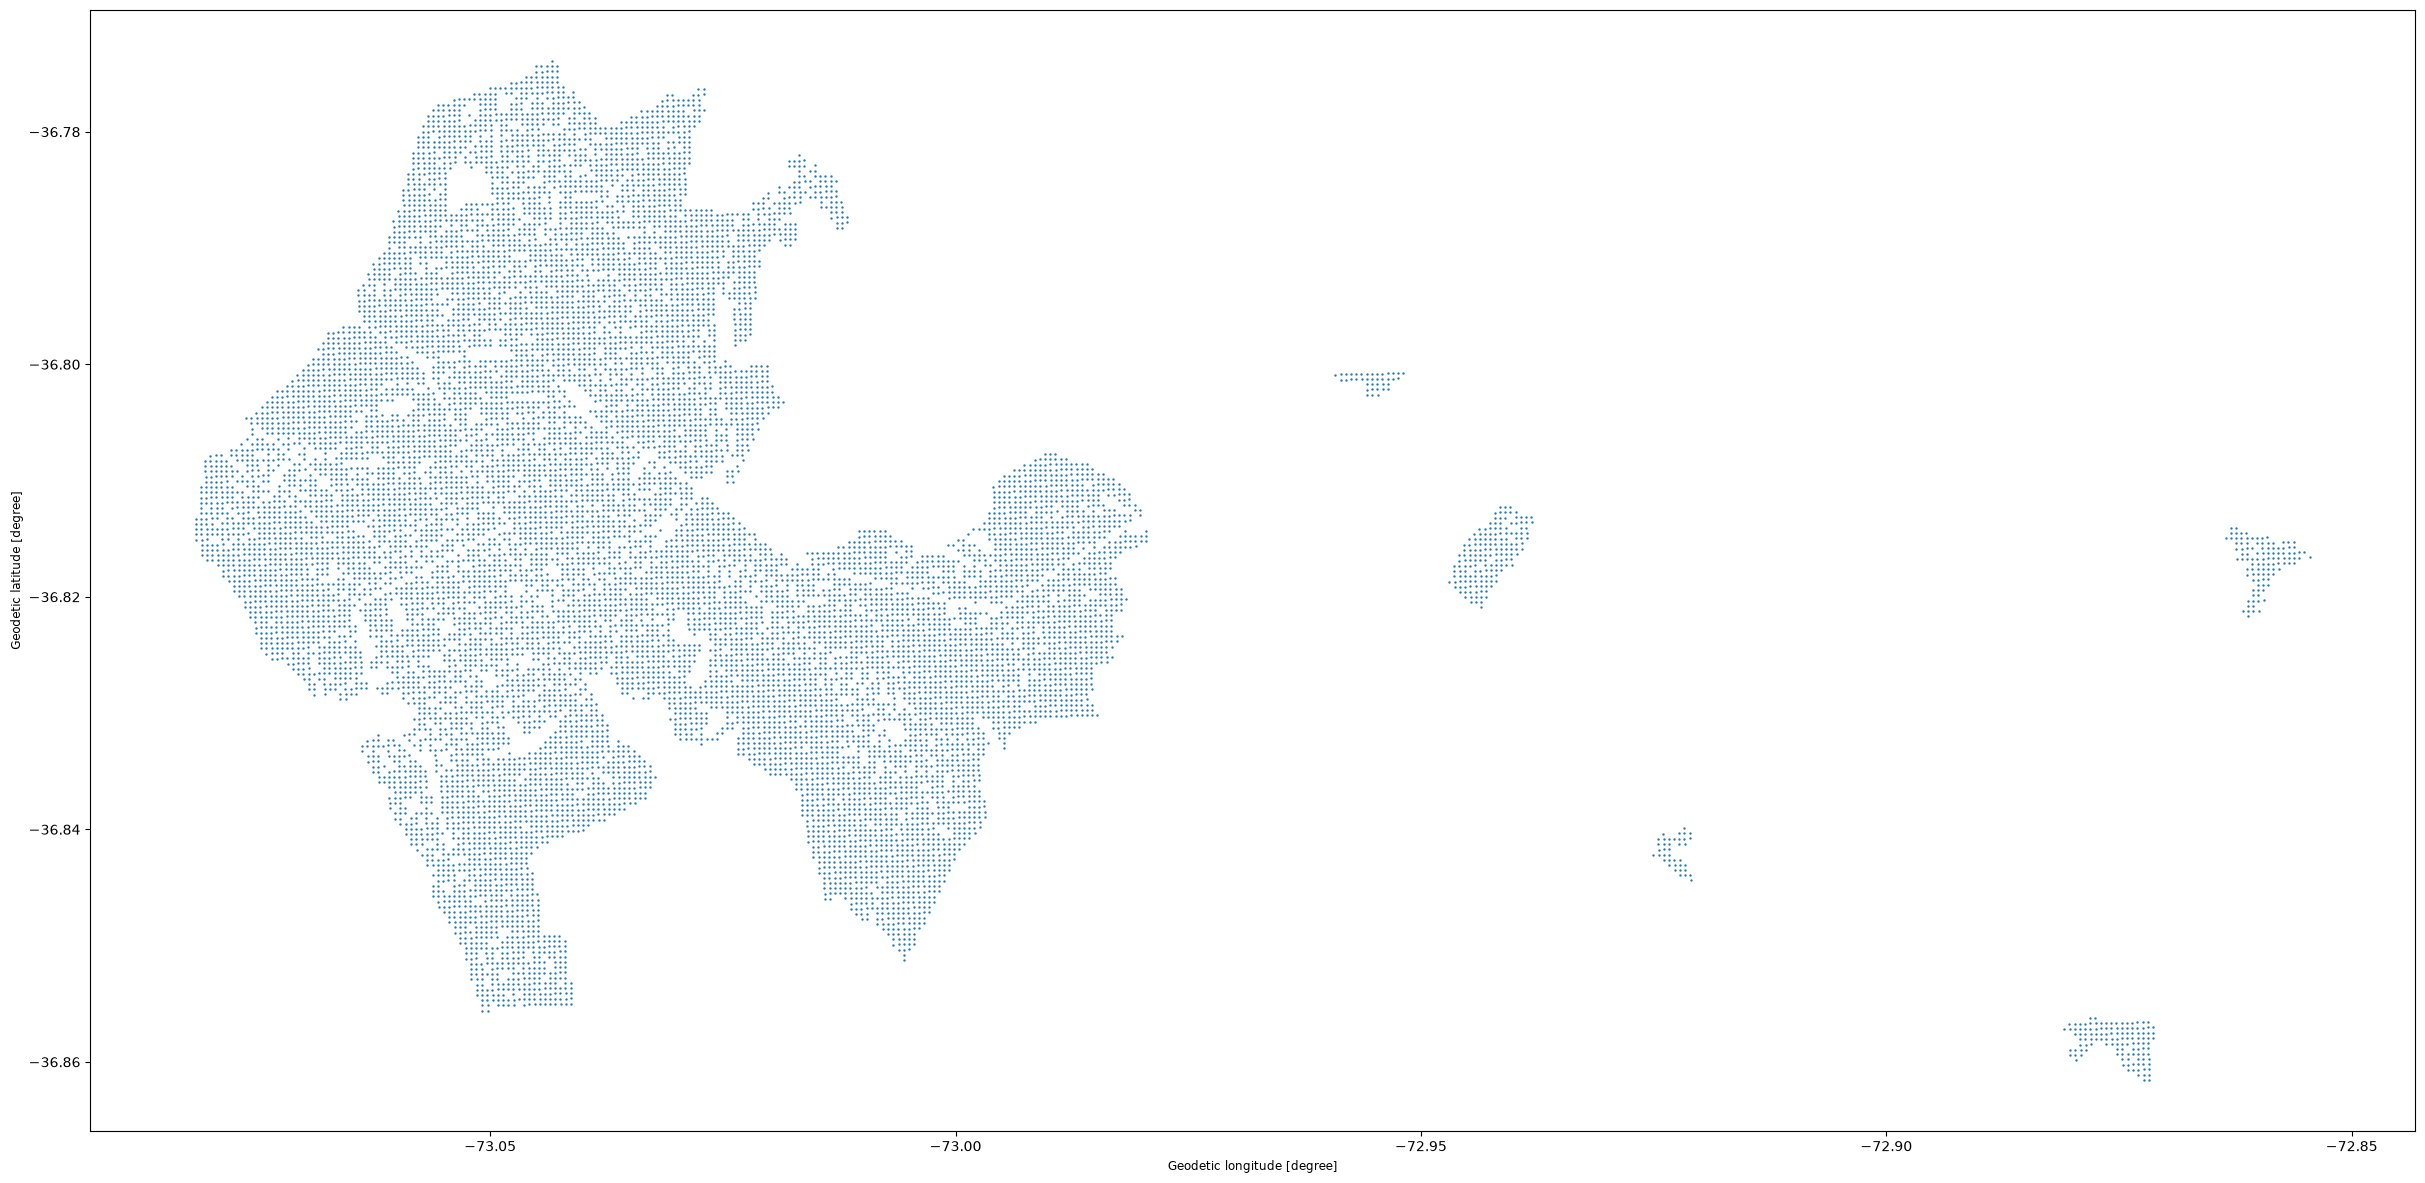

In [27]:
points_gdf.plot(figsize=(30,30), markersize=0.5)

In [28]:
# get all the h3 hexagons from all the points generated
# (which already are inside blocks with people)

points_gdf["cell"] = points_gdf.apply(lambda p: h3.latlng_to_cell(p.y, p.x, h3_resolution), 1)
cells = points_gdf.cell
cells = cells.drop_duplicates()

hexagons = [h3.cell_to_boundary(cell) for cell in cells]

# invert coordinates as h3.cell_to_boundary returns points with
# their coordinates flipped for some reason (?)
hexagons = [[(c[1], c[0]) for c in g] for g in hexagons]

# create the polygons
polygons = shapely.polygons(hexagons)

# create the hexagons_gdf with those polygons
hexagons_gdf = gpd.GeoDataFrame({"cell": cells}, geometry=polygons, crs=4326)

hexagons_gdf

,cell,geometry
0,89b2d869823ffff,"POLYGON ((-73.04485 -36.82598, -73.04411 -36.8..."
2,89b2d86983bffff,"POLYGON ((-73.04809 -36.8246, -73.04734 -36.82..."
17,89b2d86982bffff,"POLYGON ((-73.04759 -36.82756, -73.04684 -36.8..."
20,89b2d869877ffff,"POLYGON ((-73.05083 -36.82617, -73.05008 -36.8..."
38,89b2d869867ffff,"POLYGON ((-73.05033 -36.82913, -73.04958 -36.8..."
...,...,...
14073,89b2d86f22fffff,"POLYGON ((-72.94167 -36.81533, -72.94093 -36.8..."
14102,89b2d86f34bffff,"POLYGON ((-72.93793 -36.81966, -72.93719 -36.8..."
14106,89b2d86f35bffff,"POLYGON ((-72.93844 -36.81671, -72.9377 -36.81..."
14122,89b2d86f353ffff,"POLYGON ((-72.93571 -36.81514, -72.93497 -36.8..."


In [29]:
import os

try:
    os.mkdir(f"data/{place_string}")
except:
    print(f"data/{place_string} already exists")
    pass

data/concepción already exists


In [30]:
points_gdf = points_gdf[["x", "y", "cell", "geometry"]]
points_gdf.to_parquet(f"data/{place_string}/points_{spacing}m.parquet")
points_gdf.head()

,x,y,cell,geometry
0,-73.047159,-36.823538,89b2d869823ffff,POINT (-73.04716 -36.82354)
1,-73.047708,-36.823998,89b2d869823ffff,POINT (-73.04771 -36.824)
2,-73.048280,-36.823556,89b2d86983bffff,POINT (-73.04828 -36.82356)
3,-73.047719,-36.823547,89b2d86983bffff,POINT (-73.04772 -36.82355)
4,-73.047731,-36.823097,89b2d86983bffff,POINT (-73.04773 -36.8231)


In [31]:
hexagons_gdf.to_parquet(f"data/{place_string}/hexagons_{h3_resolution}.parquet")
hexagons_gdf.head()

,cell,geometry
0,89b2d869823ffff,"POLYGON ((-73.04485 -36.82598, -73.04411 -36.8..."
2,89b2d86983bffff,"POLYGON ((-73.04809 -36.8246, -73.04734 -36.82..."
17,89b2d86982bffff,"POLYGON ((-73.04759 -36.82756, -73.04684 -36.8..."
20,89b2d869877ffff,"POLYGON ((-73.05083 -36.82617, -73.05008 -36.8..."
38,89b2d869867ffff,"POLYGON ((-73.05033 -36.82913, -73.04958 -36.8..."


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

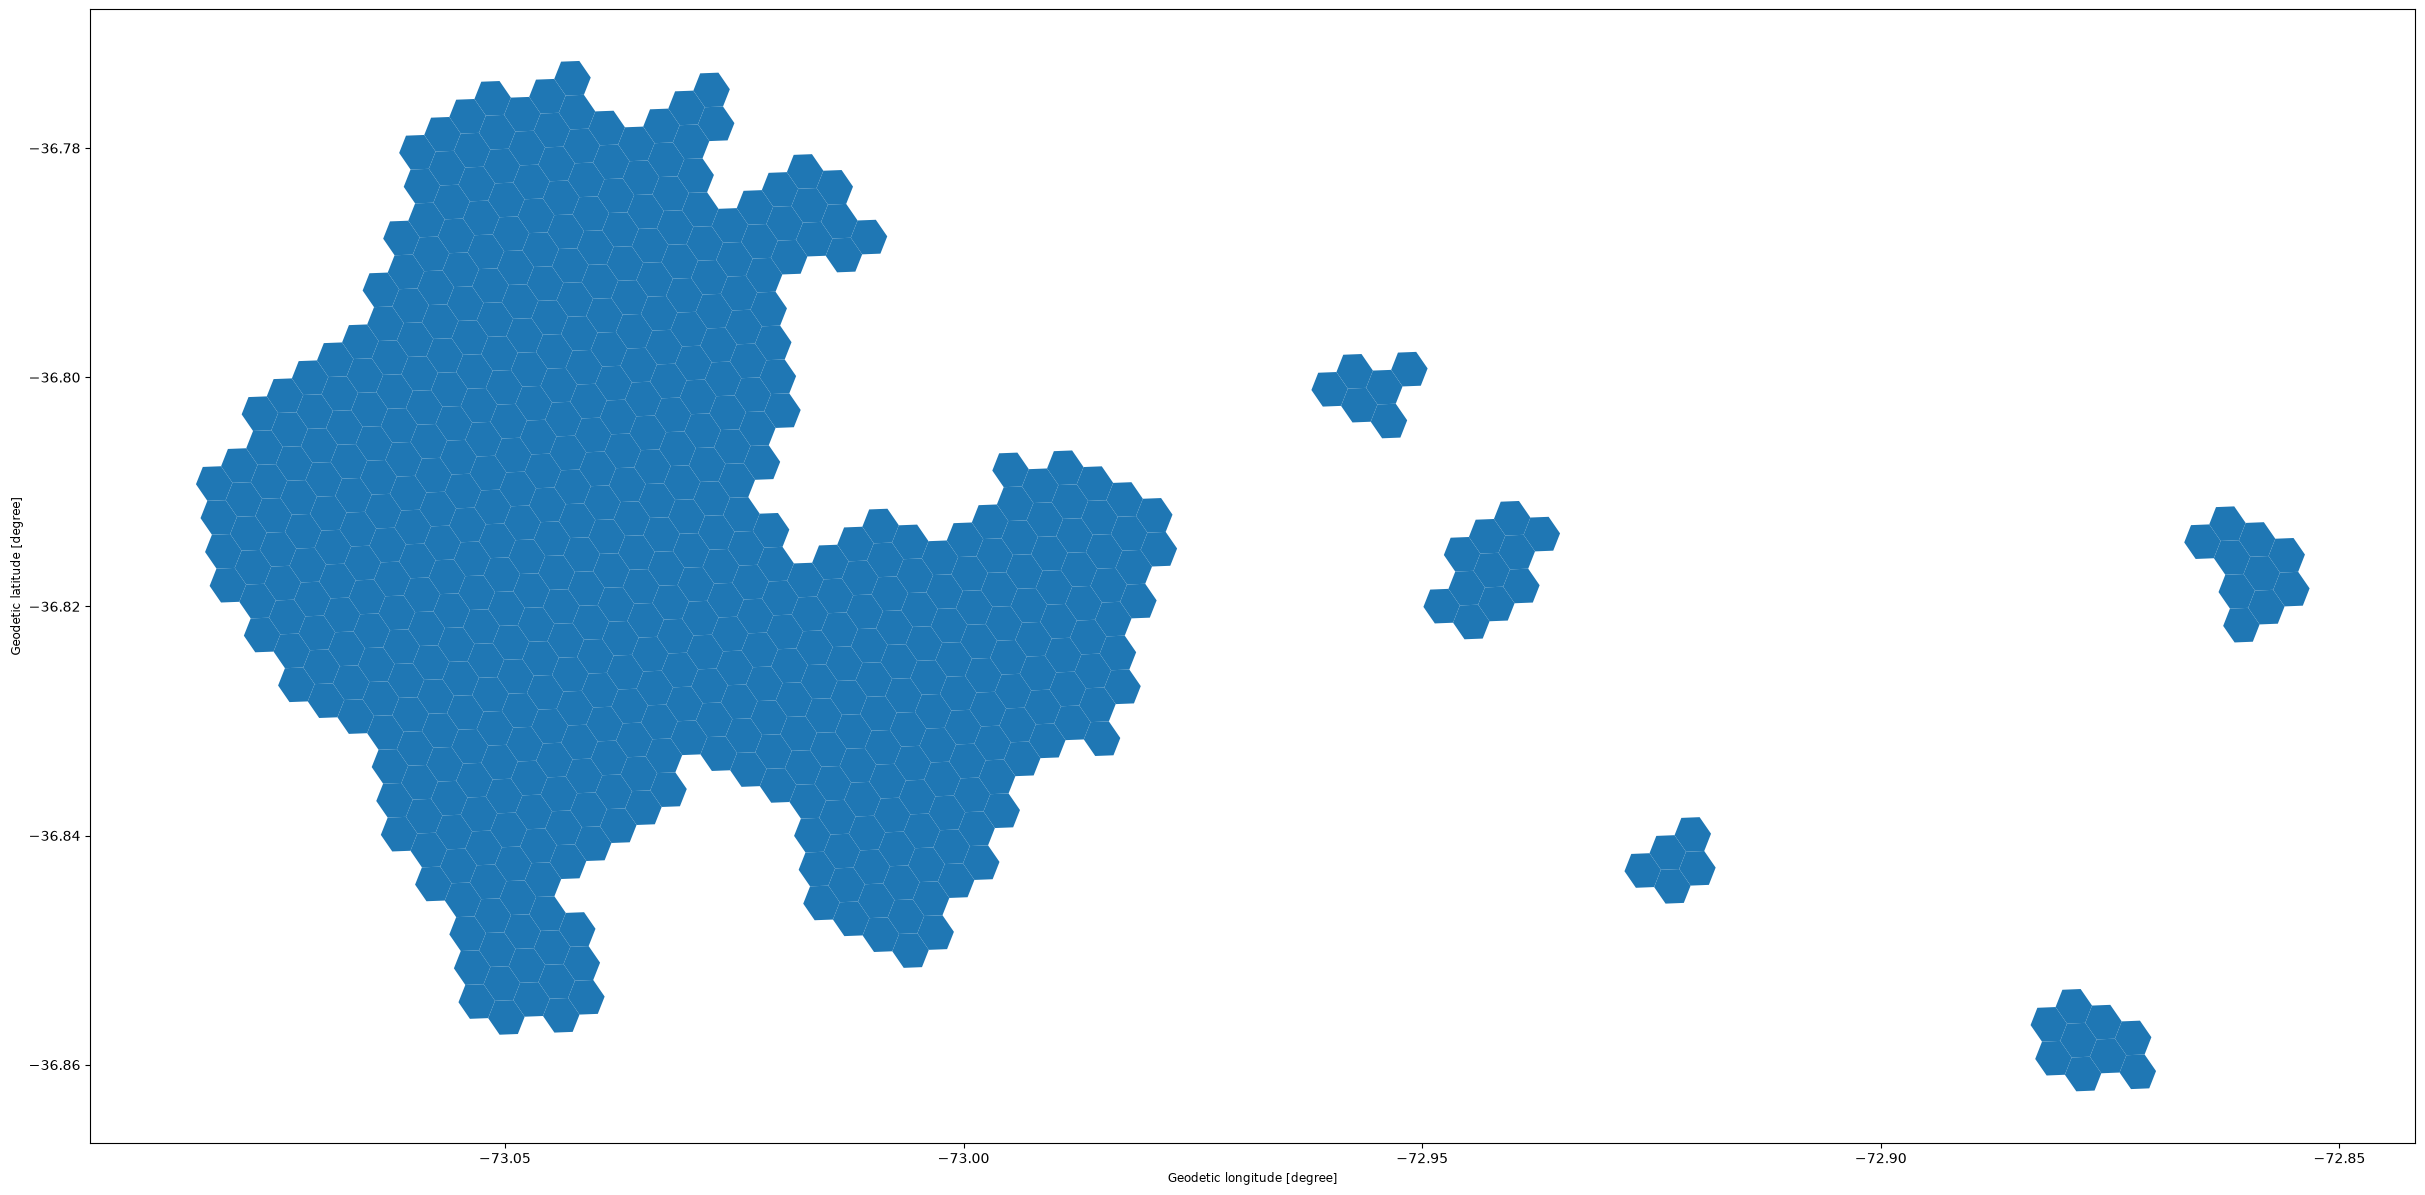

In [32]:
hexagons_gdf.plot(figsize=(30,30))